In [1]:
import sys,json,os,warnings
warnings.filterwarnings('ignore')
sys.path.insert(0,'../scripts')
import numpy as np,pandas as pd,matplotlib.pyplot as plt,matplotlib.dates as mdates
from common import *
ACC="#20808D";MUTE="#9a9a94";INK="#2b2b2b";BAD="#C8452F"
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'font.size':10,'axes.edgecolor':MUTE,'axes.labelcolor':INK,'xtick.color':INK,'ytick.color':INK,'axes.titlesize':11.5,'axes.titleweight':'bold','axes.titlelocation':'left','figure.dpi':130,'savefig.bbox':'tight','lines.linewidth':2})
M='../outputs/metrics.json'
def save_metrics(k,v):
    d=json.load(open(M)) if os.path.exists(M) else {}
    d[k]=v;json.dump(d,open(M,'w'),indent=1,default=float)
pd.set_option('display.width',160)


# 1. Panel and coverage
Vahan state by month, two-wheeler classes, all fuels versus ELECTRIC(BOV) plus PURE EV. The check here is whether the panel can carry the design at all.

In [2]:
p=pd.read_csv('../data/processed/vahan_2w_panel.csv',parse_dates=['date'])
c=pd.read_csv('../data/policy/treatment_coding.csv')
a=p.groupby('year')[['regs_2w','regs_e2w']].sum();a['e2w_share_pct']=(100*a.regs_e2w/a.regs_2w).round(2)
a.to_csv('../outputs/tables/national_by_year.csv');print(a)
print(p.state.nunique(),p.date.nunique(),len(p),p.regs_2w.isna().sum())
save_metrics('panel',{'states':p.state.nunique(),'months':p.date.nunique(),'rows':len(p),'share_2019':a.e2w_share_pct[2019],'share_2023':a.e2w_share_pct[2023],'share_2026_ytd':a.e2w_share_pct[2026]})

       regs_2w  regs_e2w  e2w_share_pct
year                                   
2017  18822774      1517           0.01
2018  20387336     17828           0.09
2019  19469203     30971           0.16
2020  15032092     30144           0.20
2021  14522511    164199           1.13
2022  16191918    661635           4.09
2023  17708342    901806           5.09
2024  19648521   1214769           6.18
2025  21019720   1342296           6.39
2026  19099035   1796515           9.41
36 118 4248 0


## Independent cross-check
A separate public copy of Vahan EV counts, pulled in early 2024, is compared month by month. Vahan revises old months slightly, so exact equality is not expected.

In [3]:
o=pd.read_csv('../data/raw/crosscheck_github_copy_2024.csv',parse_dates=['date'])
m=p.merge(o,on=['state','date']);m=m[m.date<'2024-01-01']
x={'rows':len(m),'states':m.state.nunique(),'corr':m.regs_e2w.corr(m.e2w_2024_copy),'sum_ours':int(m.regs_e2w.sum()),'sum_copy':int(m.e2w_2024_copy.sum()),'exact_match_share':(m.regs_e2w==m.e2w_2024_copy).mean()}
print(x);save_metrics('crosscheck',x)

{'rows': 2849, 'states': 34, 'corr': np.float64(0.9999823348222958), 'sum_ours': 1726229, 'sum_copy': 1722176, 'exact_match_share': np.float64(0.8125658125658126)}


## Size floor and thin cells

In [4]:
b=p[p.year==2019].groupby('state').regs_2w.sum().sort_values();print(b.head(9))
w=p[(p.date>='2019-01-01')&(p.date<='2023-12-01')]
print('zero-denominator cells in window',w[w.regs_2w==0][['state','date']].values.tolist())
print('cells under 100 two-wheelers, excluding the seven small units:',(w[~w.state.isin(c[c.group=='excluded'].state)].regs_2w<100).sum())

state
LADAKH                        280
LAKSHADWEEP                  1455
SIKKIM                       4013
NAGALAND                     5863
ANDAMAN & NICOBAR ISLAND     6656
UT OF DNH AND DD            11503
MEGHALAYA                   16603
ARUNACHAL PRADESH           21636
MIZORAM                     22844
Name: regs_2w, dtype: int64
zero-denominator cells in window [['JAMMU AND KASHMIR', Timestamp('2020-05-01 00:00:00')], ['LADAKH', Timestamp('2020-05-01 00:00:00')], ['LADAKH', Timestamp('2020-06-01 00:00:00')]]
cells under 100 two-wheelers, excluding the seven small units: 13


## The Chandigarh problem
Chandigarh's policy also capped petrol two-wheeler registrations, and the yearly cap ran out in early 2023. Registrations collapse in February and March 2023 and reset in April, so the share spikes from the denominator. That is a petrol ban, not a subsidy effect. See `docs/DATA_QUALITY_LOG.md`.

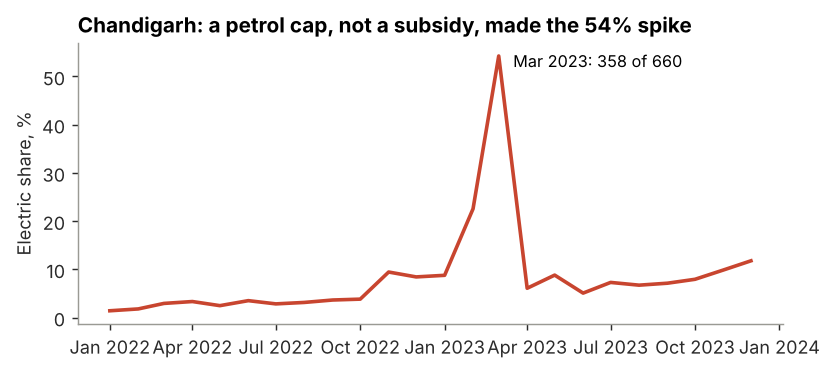

In [5]:
ch=p[(p.state=='CHANDIGARH')&(p.date>='2022-01-01')&(p.date<='2023-12-01')].copy();ch['s']=100*ch.regs_e2w/ch.regs_2w
fig,ax=plt.subplots(figsize=(7,2.8));ax.plot(ch.date,ch.s,color=BAD);ax.set_ylabel('Electric share, %')
ax.set_title('Chandigarh: a petrol cap, not a subsidy, made the 54% spike');ax.annotate('Mar 2023: 358 of 660',(pd.Timestamp('2023-03-01'),54.2),xytext=(8,-6),textcoords='offset points',fontsize=9)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'));plt.savefig('../outputs/charts/chandigarh_spike.png');plt.show()
save_metrics('chandigarh',{'mar23_regs':660,'mar23_ev':358,'mar23_share':54.2})

## Raw comparison

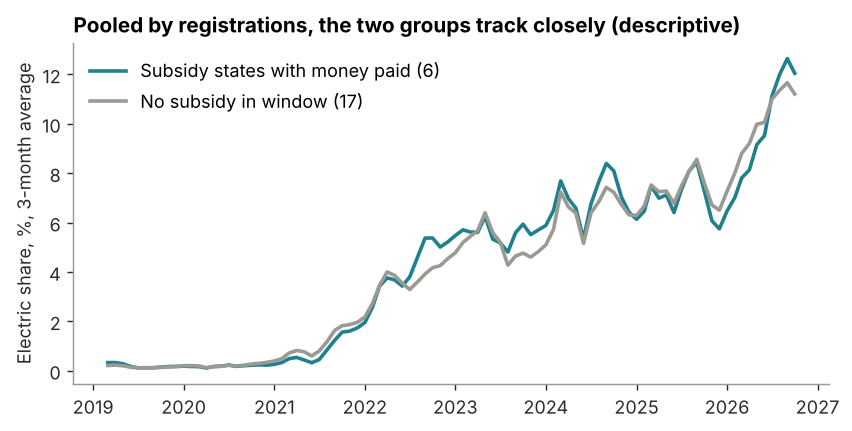

group  control  paid
y                   
2019      0.16  0.20
2020      0.24  0.19
2021      1.27  0.99
2022      3.87  4.28
2023      5.11  5.53
2024      6.47  6.73
2025      7.09  6.61
2026     10.20  9.98
group  control   paid
y                    
2019      0.07   0.15
2020      0.07   0.17
2021      0.88   1.47
2022      2.54   6.12
2023      2.16   7.94
2024      3.47   7.88
2025      3.52   8.18
2026      5.13  11.71


In [6]:
P=load(end='2026-10-01');P=P[P.state!='CHANDIGARH']
q=P.groupby([P.group,'date'])[['regs_e2w','regs_2w']].sum().reset_index();q['s']=100*q.regs_e2w/q.regs_2w
q['s3']=q.groupby('group').s.transform(lambda v:v.rolling(3).mean())
fig,ax=plt.subplots(figsize=(7.5,3.4))
for g_,col,lab in [('paid',ACC,'Subsidy states with money paid (6)'),('control',MUTE,'No subsidy in window (17)')]:
    d=q[q.group==g_];ax.plot(d.date,d.s3,color=col,label=lab)
ax.set_ylabel('Electric share, %, 3-month average');ax.set_title('Pooled by registrations, the two groups track closely (descriptive)');ax.legend(frameon=False,loc='upper left')
plt.savefig('../outputs/charts/raw_share_by_group.png');plt.show()
y=q.assign(y=q.date.dt.year).groupby(['group','y'])[['regs_e2w','regs_2w']].sum();y=(100*y.regs_e2w/y.regs_2w).unstack(0).round(2);print(y);y.to_csv('../outputs/tables/share_by_group_year.csv')
m_=P.assign(y=P.date.dt.year).groupby(['group','state','y'])[['regs_e2w','regs_2w']].sum().reset_index();m_['s']=100*m_.regs_e2w/m_.regs_2w
med=m_.groupby(['y','group']).s.median().unstack().round(2);print(med);med.to_csv('../outputs/tables/median_share_by_year.csv')
save_metrics('median_2023',med.loc[2023].to_dict())
save_metrics('raw',{'paid_2023':y.loc[2023,'paid'],'ctrl_2023':y.loc[2023,'control'],'paid_2019':y.loc[2019,'paid'],'ctrl_2019':y.loc[2019,'control']})